In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(3409)

xs = torch.randn(2,10,requires_grad=True)

In [3]:
xs

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]], requires_grad=True)

In [4]:
xs.exp()

tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.5808, 0.4321, 0.1478, 0.1463, 0.6565, 0.7502, 2.1630, 2.2060, 1.3330,
         0.6342]], grad_fn=<ExpBackward0>)

In [5]:
xs.grad

In [6]:
loss = xs.exp().sum()

In [7]:
loss.backward()

In [8]:
xs.grad

tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.5808, 0.4321, 0.1478, 0.1463, 0.6565, 0.7502, 2.1630, 2.2060, 1.3330,
         0.6342]])

In [9]:
# how to draw charts for these values

In [10]:
torch.manual_seed(3409)

xs = torch.randn(2,10,requires_grad=True)

In [11]:
# draw plots
arr = []
arr1 = []

In [12]:
targets = torch.tensor([5,5])

In [13]:
xs.sum(-1)

tensor([ 4.3301, -4.5300], grad_fn=<SumBackward1>)

In [14]:
targets - xs.sum(-1)

tensor([0.6699, 9.5300], grad_fn=<SubBackward0>)

In [15]:
# mean / sum --> mean
((targets - xs.sum(-1)) ** 2).mean()

tensor(45.6352, grad_fn=<MeanBackward0>)

In [16]:
LR = 0.001
for i in range(100):
    #logits = xs.exp()
    logits = xs
    #loss = xs.exp().sum()
    #loss = (xs ** 2).sum()
    loss = ((targets - xs.sum(-1)) ** 2).mean()
    print(loss)

    test_loss = torch.nn.MSELoss()
    #print(test_loss(logits, torch.

    if xs.grad != None:
        arr1.append(xs.data[0][0].item())
        arr.append(xs.grad[0][0].item())
    
    xs.grad = None
    loss.backward()
    #print(loss.item())
    xs.data -= xs.grad * LR

print(loss.item())

tensor(45.6352, grad_fn=<MeanBackward0>)
tensor(44.7271, grad_fn=<MeanBackward0>)
tensor(43.8370, grad_fn=<MeanBackward0>)
tensor(42.9646, grad_fn=<MeanBackward0>)
tensor(42.1096, grad_fn=<MeanBackward0>)
tensor(41.2716, grad_fn=<MeanBackward0>)
tensor(40.4503, grad_fn=<MeanBackward0>)
tensor(39.6454, grad_fn=<MeanBackward0>)
tensor(38.8564, grad_fn=<MeanBackward0>)
tensor(38.0832, grad_fn=<MeanBackward0>)
tensor(37.3253, grad_fn=<MeanBackward0>)
tensor(36.5826, grad_fn=<MeanBackward0>)
tensor(35.8546, grad_fn=<MeanBackward0>)
tensor(35.1411, grad_fn=<MeanBackward0>)
tensor(34.4418, grad_fn=<MeanBackward0>)
tensor(33.7564, grad_fn=<MeanBackward0>)
tensor(33.0846, grad_fn=<MeanBackward0>)
tensor(32.4262, grad_fn=<MeanBackward0>)
tensor(31.7809, grad_fn=<MeanBackward0>)
tensor(31.1485, grad_fn=<MeanBackward0>)
tensor(30.5286, grad_fn=<MeanBackward0>)
tensor(29.9211, grad_fn=<MeanBackward0>)
tensor(29.3257, grad_fn=<MeanBackward0>)
tensor(28.7421, grad_fn=<MeanBackward0>)
tensor(28.1701, 

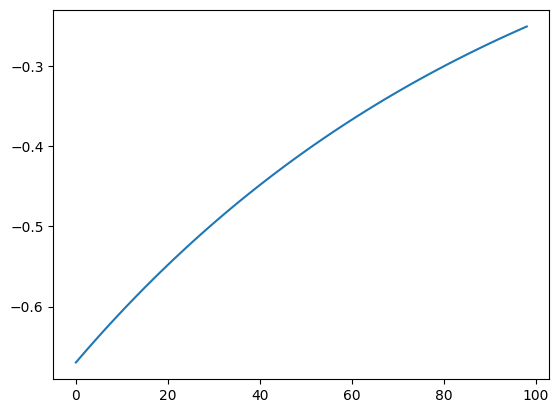

In [17]:
plt.plot(arr)

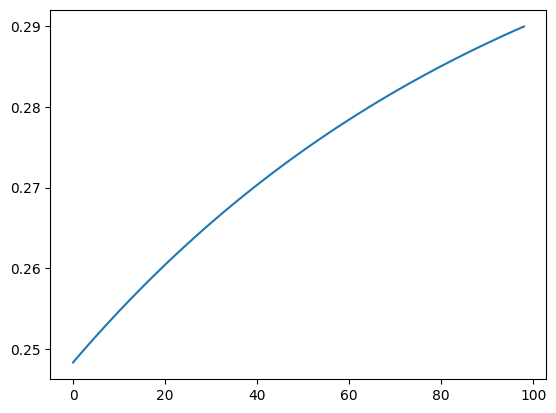

In [18]:
plt.plot(arr1)

In [19]:
torch.tensor(arr1[20]).exp()

tensor(1.2975)

In [20]:
arr[20]

-0.5478887557983398

In [21]:
# we need positive values only, that's why EXP() comes here
# if TURE for (xs < 0).any() that's we need .exp() for probs

In [22]:
(xs < 0).any()

tensor(True)

In [23]:
probs = xs.exp()
p = torch.multinomial(probs, num_samples=10)

In [24]:
xs.exp().sum(-1)

tensor([24.7117, 16.5589], grad_fn=<SumBackward1>)

In [25]:
p

tensor([[1, 8, 3, 0, 5, 9, 2, 6, 4, 7],
        [6, 5, 7, 0, 9, 8, 4, 1, 2, 3]])

In [26]:
# simple neuron

In [27]:
torch.manual_seed(3409)

xs = torch.randn(1,1,requires_grad=True)

In [28]:
xs.grad, xs.data

(None, tensor([[-0.2832]]))

In [29]:
torch.sigmoid(xs)

tensor([[0.4297]], grad_fn=<SigmoidBackward0>)

In [30]:
m = torch.nn.ReLU()
logits = m(xs.exp())
logits

tensor([[0.7534]], grad_fn=<ReluBackward0>)

In [31]:
arr = [] # loss
arr_grad = [] # grads

In [32]:
LR = 0.1
for i in range(1000):
    m = torch.nn.ReLU()
    logits = m(xs.exp())
    loss = logits
    #print( "grads " , xs.grad)
    if (xs.grad != None):
        arr_grad.append(xs.grad[0].item())
    xs.grad = None
    loss.backward()
    xs.data -= xs.grad * LR
    arr.append(loss.item())
print(loss.item())

0.009857500903308392


In [33]:
xs.grad[0].item()

0.009857500903308392

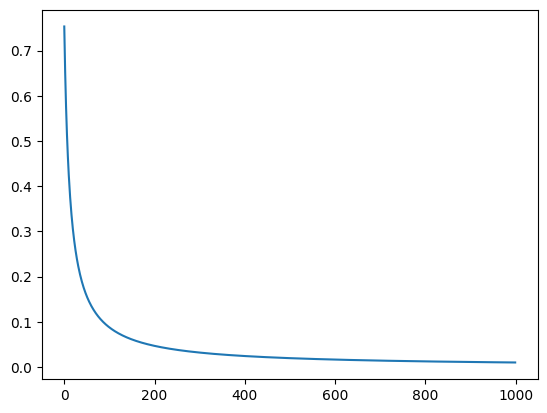

In [34]:
plt.plot(arr)

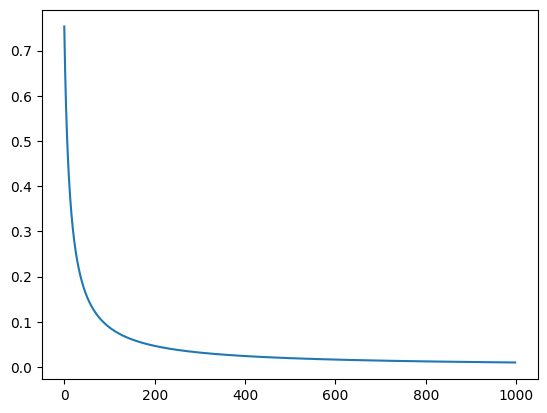

In [35]:
plt.plot(arr_grad)

In [36]:
# simple test for 3 classes 

In [37]:
torch.manual_seed(3409)

xs = torch.randn(3,1,requires_grad=True)

In [38]:
xs

tensor([[-0.2832],
        [ 0.6009],
        [ 0.0940]], requires_grad=True)

In [39]:
torch.sigmoid(xs)

tensor([[0.4297],
        [0.6459],
        [0.5235]], grad_fn=<SigmoidBackward0>)

In [40]:
torch.manual_seed(3409)

targets = torch.randint(0,27,(3,)).float()

In [41]:
targets.view(3,1)

tensor([[16.],
        [26.],
        [ 4.]])

In [42]:
m = torch.nn.MSELoss()
m(xs, targets.view(3,1))

tensor(308.5050, grad_fn=<MseLossBackward0>)

In [43]:
arr = []

In [44]:
LR = 0.1
for i in range(100):
    m = torch.nn.MSELoss()
    loss = m(xs, targets.view(3,1))
    #print(type(loss), loss.dtype)
    xs.grad = None
    loss.backward()
    #print(f" step {i} -> loss {loss.item()}")
    arr.append(loss.item())
    xs.data -= xs.grad * LR
print(loss.item())

0.0003602330107241869


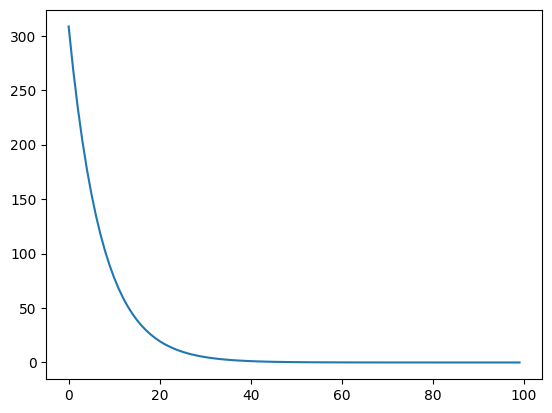

In [45]:
plt.plot(arr)

In [46]:
xs

tensor([[15.9836],
        [25.9744],
        [ 3.9961]], requires_grad=True)

In [47]:
targets

tensor([16., 26.,  4.])

In [48]:
# get predictions

In [49]:
(xs < 0).any()

tensor(False)

In [50]:
# if FALSE then no need .exp()

In [51]:
#probs = xs.exp()
probs = xs
p = torch.multinomial(probs, num_samples=10, replacement=True)

In [52]:
p

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [53]:
# more complex NN model 

In [54]:
torch.manual_seed(3409)

xs = torch.randn(3,10,requires_grad=True)

In [55]:
torch.manual_seed(3409)

targets = torch.randint(0,27,(3,)).float()

In [56]:
arr = []

In [57]:
LR = 0.1
for i in range(100):
    m = torch.nn.MSELoss()
    loss = m(xs, targets.view(3,1))
    #print(type(loss), loss.dtype)
    xs.grad = None
    loss.backward()
    #print(f" step {i} -> loss {loss.item()}")
    arr.append(loss.item())
    xs.data -= xs.grad * LR
print(loss.item())

84.10321807861328


C:\Users\kdhome\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\loss.py:535: UserWarning: Using a target size (torch.Size([3, 1])) that is different to the input size (torch.Size([3, 10])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [58]:
(xs < 0).any()

tensor(False)

In [59]:
#probs = xs.exp()
probs = xs
p = torch.multinomial(probs, num_samples=10, replacement=True)

In [60]:
p

tensor([[8, 1, 3, 6, 0, 5, 9, 0, 6, 2],
        [3, 2, 9, 6, 4, 6, 6, 4, 0, 9],
        [0, 3, 3, 1, 1, 9, 8, 1, 5, 3]])